# Piece 8B — CFD results pipeline, mesh convergence, multi-zone coach, calibration

> ## ⚠ No real CFD results are included yet
> Every CFD case in `ansys/cases/` has status **planned**; no Fluent run has been made. Everything plotted below as "CFD" is **manufactured, verification-only data**: an analytic sequence for the GCI demo, and numbers generated by the multi-zone model itself (known parameters + seeded noise) for the calibration demo. They demonstrate that the pipeline works, nothing more.

In [1]:
import sys
from pathlib import Path

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ansys.case0_inputs import case0_inputs
from core import psychro
from core.cfd_import import list_cases, load_case
from core.coach import MultiZoneCoach, SingleZoneCoach
from core.rom import ROMSetup, ValidityRange, calibrate, lhs_design, leave_one_out
from validation.case0_compare import compare_case0
from validation.gci import gci

for c in list_cases():
    case = load_case(c)
    print(f"{c:24s} status={case.file.status:8s} runs={len(case.file.runs)} "
          f"meshes={len(case.file.meshes)} open items={len(case.open_items)}")

Matplotlib is building the font cache; this may take a moment.


case0_devahldavis        status=planned  runs=4 meshes=3 open items=0
case1_chamber_section    status=planned  runs=1 meshes=3 open items=2
case2_coach_bay          status=planned  runs=1 meshes=3 open items=4


## GCI on a manufactured sequence (Celik et al. 2008)

$f(h) = f_0 + C h^2$ with $f_0 = 3$, $C = 5$ on $h = 0.01, 0.02, 0.04$ (**manufactured**). The procedure must return $p = 2$ and recover $f_0$; an oscillating sequence must be flagged.

apparent order p = 2.000000, extrapolated = 3.000000000 (f0 = 3.0)
e_a21 = 4.999e-04, GCI_fine = 0.0208 % -> f1 = 3.000500 +/- 6.25e-04
oscillating sequence (1.00, 1.10, 0.95) flagged: True


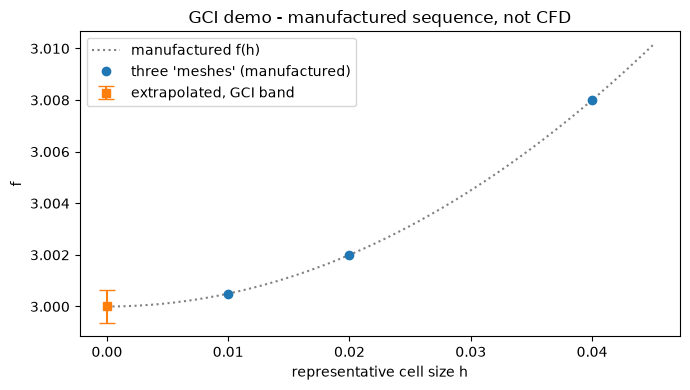

In [2]:
f0, C = 3.0, 5.0
hs = np.array([0.01, 0.02, 0.04])
f = f0 + C * hs ** 2
r = gci(*f, *hs)
print(f"apparent order p = {r.p:.6f}, extrapolated = {r.f_extrapolated:.9f} (f0 = {f0})")
print(f"e_a21 = {r.e_a21:.3e}, GCI_fine = {r.gci_fine * 100:.4f} % -> f1 = {f[0]:.6f} +/- {r.band:.2e}")
print("oscillating sequence (1.00, 1.10, 0.95) flagged:", gci(1.00, 1.10, 0.95, 1, 2, 4).oscillatory)

h_plot = np.linspace(0, 0.045, 50)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(h_plot, f0 + C * h_plot ** 2, ":", color="grey", label="manufactured f(h)")
ax.plot(hs, f, "o", label="three 'meshes' (manufactured)")
ax.errorbar([0], [r.f_extrapolated], yerr=[r.band], fmt="s", capsize=6, label="extrapolated, GCI band")
ax.set_xlabel("representative cell size h"); ax.set_ylabel("f"); ax.legend()
ax.set_title("GCI demo - manufactured sequence, not CFD"); plt.tight_layout(); plt.show()

## Case 0 inputs (de Vahl Davis cavity)

Cavity side $L$ such that $Ra = g\beta\Delta T L^3/(\nu\alpha)$ exactly, air at 20 °C from CoolProp, $\Delta T$ = 10 K, $\beta\Delta T$ below the Boussinesq limit E-123. This is the table the Fluent team copies (also `python -m ansys.case0_inputs`).

In [3]:
df0 = case0_inputs()
display(df0[["run", "Ra", "L_m", "T_hot_C", "T_cold_C", "beta_dT", "Pr", "Pr_deviation"]])
print("Comparison status (no results, benchmarks E-117..E-120 still to transcribe):")
for rc in compare_case0():
    print(f"  {rc.run}: {rc.status} - {'; '.join(rc.messages)}")

,run,Ra,L_m,T_hot_C,T_cold_C,beta_dT,Pr,Pr_deviation
0,Ra1e3,1000.0,0.009871,25.0,15.0,0.03421,0.707956,-0.002879
1,Ra1e4,10000.0,0.021266,25.0,15.0,0.03421,0.707956,-0.002879
2,Ra1e5,100000.0,0.045817,25.0,15.0,0.03421,0.707956,-0.002879
3,Ra1e6,1000000.0,0.098709,25.0,15.0,0.03421,0.707956,-0.002879


Comparison status (no results, benchmarks E-117..E-120 still to transcribe):
  Ra1e3: skipped - results missing for mesh(es) fine, medium, coarse (Fluent runs not done yet)
  Ra1e4: skipped - results missing for mesh(es) fine, medium, coarse (Fluent runs not done yet)
  Ra1e5: skipped - results missing for mesh(es) fine, medium, coarse (Fluent runs not done yet)
  Ra1e6: skipped - results missing for mesh(es) fine, medium, coarse (Fluent runs not done yet)


## Calibration of the multi-zone coach — MANUFACTURED data

A Latin-hypercube design over supply airflow, outside temperature, solar intensity and occupancy (12 runs). The "CFD" zone temperatures are generated by the multi-zone model with **known** parameters ($G_{mix}$ = 300 W/K, supply fractions 0.40 / 0.35 / 0.25, $A_{sol}$ = 20 m²) plus 0.02 K noise, then fitted from a neutral start. Verification-only coach: A = 300 m², k = 1.2 W/m²K, C = 5·10⁶ J/K; return air from the back zone.

In [4]:
base = SingleZoneCoach("verification", 300.0, 1.2, 5e6, air_volume_m3=150.0)
setup = ROMSetup(MultiZoneCoach(base, return_weight=(0.0, 0.0, 1.0), solar_share=(0.2, 0.3, 0.5)),
                 supply_T_C=14.0, supply_W=psychro.humidity_ratio(14.0, 0.8), pax_sensible_W=70.0)
factors = {"supply_airflow_m3_h": (3000.0, 6000.0), "outside_T_C": (25.0, 45.0),
           "solar_W_m2": (0.0, 800.0), "occupancy": (0.0, 80.0)}
design = lhs_design(factors, 12, seed=1)
true = setup.theta(300.0, (0.40, 0.35, 0.25), 20.0)
start = setup.theta(100.0, (1 / 3, 1 / 3, 1 / 3), 10.0)
cfd_like = setup.predict_all(true, design) + np.random.default_rng(7).normal(0, 0.02, (12, 3))

cal = calibrate(setup, design, cfd_like, start)
print("fitted:", {k: (np.round(v, 4) if isinstance(v, tuple) else round(v, 3)) for k, v in cal.parameters.items()})
print("true  : G_mix 300, fractions (0.40, 0.35, 0.25), A_sol 20")
print("RMS [K]:", {k: round(v, 4) for k, v in cal.rms.items()})
print("max [K]:", {k: round(v, 4) for k, v in cal.max_abs.items()})
display(design.round(1))

fitted: {'G_mix_W_K': 311.713, 'supply_fraction': array([0.4015, 0.3499, 0.2486]), 'A_sol_m2': 19.967}
true  : G_mix 300, fractions (0.40, 0.35, 0.25), A_sol 20
RMS [K]: {'T_front': 0.0146, 'T_middle': 0.0177, 'T_back': 0.0185, 'spread': 0.021}
max [K]: {'T_front': 0.0293, 'T_middle': 0.0326, 'T_back': 0.0463, 'spread': 0.0595}


,run_id,supply_airflow_m3_h,outside_T_C,solar_W_m2,occupancy
0,R01,4872.0,26.7,523.7,7.0
1,R02,5672.0,44.3,278.2,63.9
2,R03,5362.6,40.0,616.4,23.1
3,R04,4417.6,32.0,179.8,70.3
4,R05,4216.5,34.3,386.4,31.6
5,R06,3062.4,42.9,434.3,40.1
6,R07,4509.6,30.5,563.9,58.2
7,R08,5209.8,35.1,32.3,19.2
8,R09,3844.1,40.4,225.8,47.2
9,R10,3490.1,29.1,769.4,79.6


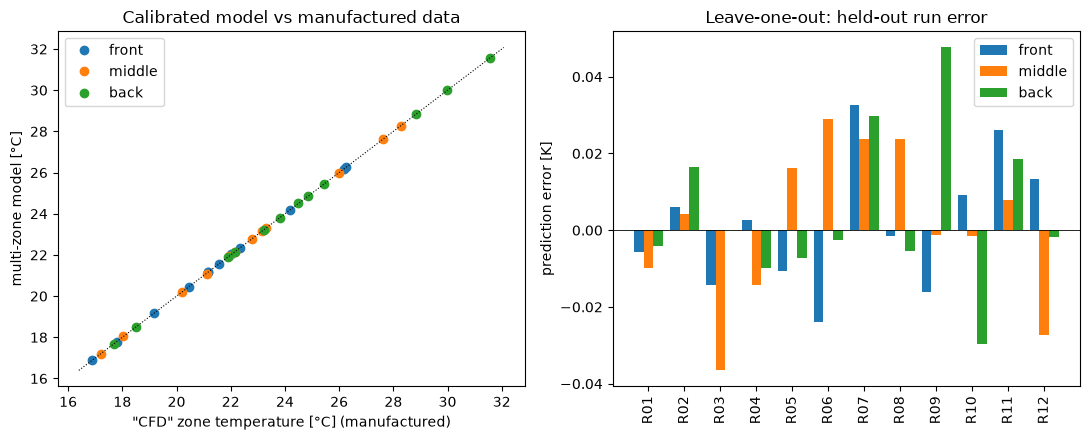

leave-one-out max |error| = 0.064 K
validity range (DOE bounding box): {'supply_airflow_m3_h': (3062.4, 5839.7), 'outside_T_C': (25.2, 44.3), 'solar_W_m2': (32.3, 769.4), 'occupancy': (1.6, 79.6)}
check at 48 degC outside: ['ROM validity: outside_T_C = 48 is outside the calibrated range 25.2456 .. 44.2945 (extrapolation)']


In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.5))
for z in ("front", "middle", "back"):
    a1.plot(cal.observed[f"T_{z}"], cal.predicted[f"T_{z}"], "o", label=z)
lims = [cal.observed.filter(like="T_").min().min() - 0.5, cal.observed.filter(like="T_").max().max() + 0.5]
a1.plot(lims, lims, "k:", lw=0.8)
a1.set_xlabel('"CFD" zone temperature [°C] (manufactured)'); a1.set_ylabel("multi-zone model [°C]")
a1.set_title("Calibrated model vs manufactured data"); a1.legend()

loo = leave_one_out(setup, design, cfd_like, start)
x = np.arange(len(loo))
for k, z in enumerate(("front", "middle", "back")):
    a2.bar(x + (k - 1) * 0.27, loo[f"err_T_{z}"], width=0.27, label=z)
a2.axhline(0, color="k", lw=0.6)
a2.set_xticks(x, loo["run_id"], rotation=90); a2.set_ylabel("prediction error [K]")
a2.set_title("Leave-one-out: held-out run error"); a2.legend()
plt.tight_layout(); plt.show()
print(f"leave-one-out max |error| = {loo['max_abs_err'].max():.3f} K")
print("validity range (DOE bounding box):", {k: tuple(round(v, 1) for v in b) for k, b in cal.validity.bounds.items()})
print("check at 48 degC outside:", cal.validity.check({"outside_T_C": 48.0}))